In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.layers import Layer
import keras 

from matplotlib import pyplot as plt
tf.random.set_seed(42)

In [ ]:
IMAGE_SIZE = 256
BATCH_SIZE = 16
CHANNELS = 3
EPOCHS = 100
TIMESTEPS = 500
LEARNING_RATE = 1e-4
FILE_NAME = "upsample-dogs.weights.h5"
IS_TRAINING = False

print(IMAGE_SIZE, BATCH_SIZE, CHANNELS, EPOCHS, TIMESTEPS, LEARNING_RATE, FILE_NAME)

In [ ]:
DATASET_PATH = './afhq/train/dog'
LOW_RES_SIZE = 64
HIGH_RES_SIZE = 256

def preprocess(images):
    # Convert to float
    images = tf.cast(images, tf.float32)
    # Map from [0, 255] to [-1, 1]
    images = (images / 127.5) - 1.0
    return images

def preprocess_and_create_pairs(images):
    """Preprocess images and create low-res/high-res pairs for upscaling training"""
    # Convert to float
    images = tf.cast(images, tf.float32)

    # Create low resolution version (this is our input)
    low_res = tf.image.resize(
        images,
        size=[LOW_RES_SIZE, LOW_RES_SIZE],
        method='bicubic',
        antialias=True  # Important for clean downsampling
    )
    
    # First resize to high resolution (this is our target)
    high_res = tf.image.resize(
        low_res,
        size=[HIGH_RES_SIZE, HIGH_RES_SIZE],
        method='bicubic',
        antialias=True
    )
    
    # Normalize all to [-1, 1]
    images = (images / 127.5) - 1.0
    high_res = (high_res / 127.5) - 1.0
    
    # Return as a tuple (low_res, high_res)
    return images, high_res

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    labels=None,        # We only need images for basic diffusion
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    image_size=(IMAGE_SIZE, IMAGE_SIZE), # Resizes automatically
    shuffle=True,
    seed=42,
    interpolation='bilinear'
)

# Apply the preprocessing
train_ds = train_ds.map(preprocess_and_create_pairs)
x_train = train_ds.cache().shuffle(buffer_size=500).prefetch(buffer_size=tf.data.AUTOTUNE)
TOTAL_STEPS = len(x_train) * EPOCHS

    
print("Dataset is ready for training!")

In [ ]:
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=LEARNING_RATE,
    decay_steps=TOTAL_STEPS,
    alpha=0.1  # Minimum learning rate = 0.1 × initial
)
optimizer = tf.keras.optimizers.Adam(learning_rate=lr_schedule)
loss_fn = tf.keras.losses.MeanSquaredError()

# create a fixed linear beta schedule
beta_start = 0.0001
beta_end = 0.02
beta = tf.linspace(beta_start, beta_end, TIMESTEPS)

alpha = 1 - beta
alpha_bar = tf.math.cumprod(alpha, axis=0)
alpha_bar = tf.concat([tf.constant([1.0]), alpha_bar[:-1]], axis=0)
sqrt_alpha_bar = tf.math.sqrt(alpha_bar)
sqrt_one_minus_alpha_bar = tf.math.sqrt(1-alpha_bar)


# this function will add noise to the input as per the given timestamp
@tf.function
def forward_noise(x_0, t):
    noise = tf.random.normal(shape=tf.shape(x_0), dtype=tf.float32)
    batch_sqrt_alpha = tf.gather(sqrt_alpha_bar, t)
    batch_sqrt_one_minus_alpha_bar = tf.gather(sqrt_one_minus_alpha_bar, t)

    reshaped_sqrt_alpha = tf.reshape(batch_sqrt_alpha, (-1, 1, 1, 1))
    reshaped_sqrt_one_minus_alpha_bar = tf.reshape(batch_sqrt_one_minus_alpha_bar, (-1, 1, 1, 1))

    # Applying the actual formula
    noisy_image = (reshaped_sqrt_alpha * x_0) + (reshaped_sqrt_one_minus_alpha_bar * noise)
    return noisy_image, noise

# this function will be used to create sample timestamps between 0 &amp; T
@tf.function
def generate_timestamp(num):
    return tf.random.uniform(shape=[num], minval=0, maxval=TIMESTEPS, dtype=tf.int32)

In [ ]:
@keras.saving.register_keras_serializable()
class SinusoidalPosEmb(Layer):
    def __init__(self, dim=64, max_positions=10000):
        super(SinusoidalPosEmb, self).__init__()
        self.dim = dim
        self.max_positions = max_positions

    def call(self, x, training=True):
        x = tf.cast(x, tf.float32)
        half_dim = self.dim // 2

        emb = tf.math.log(tf.cast(self.max_positions, tf.float32)) / (half_dim - 1)
        emb = tf.math.exp(tf.range(half_dim, dtype=tf.float32) * -emb)
        emb = x[:, None] * emb[None, :]
        emb = tf.concat([tf.math.sin(emb), tf.math.cos(emb)], axis=-1)

        return emb

@keras.saving.register_keras_serializable()
class TimeEmbedding(Layer):
    def __init__(self, dim=64, **kwargs):
        super(TimeEmbedding, self).__init__(**kwargs)
        self.dim = dim
        self.time_emb = 4*dim

        self.emb = SinusoidalPosEmb(dim)
        self.dense1 = layers.Dense(self.time_emb)
        self.act = layers.Activation("swish")
        self.dense2 = layers.Dense(self.time_emb)

    def call(self, x, training=True):
        x = self.emb(x)
        x = self.dense1(x)
        x = self.act(x)
        x = self.dense2(x)
        return x

@keras.saving.register_keras_serializable()
class Attention(Layer):
    def __init__(self, dim, num_heads=8, **kwargs):
        super(Attention, self).__init__(**kwargs)
        self.dim = dim
        self.num_heads = num_heads
        self.head_dim = dim // num_heads 
        
        self.mha = layers.MultiHeadAttention(num_heads=num_heads, key_dim=self.head_dim)

    def call(self, x):
        batch_size = tf.shape(x)[0]
        h, w = x.shape[1], x.shape[2]
        
        flat_x = tf.reshape(x, (batch_size, h*w, self.dim))
        attn_x = self.mha(flat_x, flat_x)
        
        out_x = tf.reshape(attn_x, (batch_size, h, w, self.dim))
        return out_x

@keras.saving.register_keras_serializable()
class Block(Layer):
    def __init__(self, dim=64, **kwargs):
        super(Block, self).__init__(**kwargs)
        self.conv = layers.Conv2D(dim, (3,3), padding="same")
        self.norm = layers.GroupNormalization(groups=8)
        self.act = layers.Activation("swish")
    
    def call(self, x, training=True):
        x = self.conv(x)
        x = self.norm(x)
        x = self.act(x)
        return x

@keras.saving.register_keras_serializable()
class ResNetBlock(layers.Layer):
    def __init__(self, out_channels=64, **kwargs):
        super(ResNetBlock, self).__init__(**kwargs)
        self.out_channels = out_channels
        
        # --- BLOCK 1 ---
        self.conv_block1 = Block(out_channels)

        # --- TIME PROCESSING ---
        # Takes the time vector and formats it to match the image channels
        self.time_dense = layers.Dense(out_channels)
        self.time_act = layers.Activation("swish")

        # --- BLOCK 2 ---
        self.conv_block2 = Block(out_channels)

        # --- RESIDUAL MATCHING ---
        # A 1x1 Conv to ensure input shape matches output shape for adding
        self.res_conv = layers.Conv2D(out_channels, 1, padding="same")

    def call(self, x, t_emb=None):
        # 1. Save input for later (Residual connection)
        input_x = x
        
        # 2. First Convolution Block
        h = self.conv_block1(input_x)

        # 3. Inject Time (CRITICAL STEP)
        if t_emb is not None:
            # Process time
            t = tf.squeeze(t_emb, axis=1)
            t = self.time_act(t)
            t = self.time_dense(t)
            # Reshape time to (Batch, 1, 1, Channels) so it broadcasts over the image
            t = tf.expand_dims(tf.expand_dims(t, 1), 1)
            # Add time to the image features
            h = h + t

        # 4. Second Convolution Block
        h = self.conv_block2(h)

        # 5. Residual Connection
        # We transform the original input to match the output channels
        residual = self.res_conv(input_x)
        
        # Return: Original(transformed) + New Learned Features
        return h + residual


In [ ]:
def build_unet(img_size):
    dim = 32
    dim_scale_factor = (1, 2, 4, 8)
    ATTN_RESOLUTIONS = (16, 8)
    num_groups = 8
    channels = CHANNELS

    image_input = layers.Input(shape=(img_size, img_size, channels+channels), name="image_input")
    time_input = layers.Input(shape=(1,), name="time_input")

    t_emb = TimeEmbedding(dim)(time_input)

    x = layers.Conv2D(dim, kernel_size=7, padding="same")(image_input)

    skips = [] # List to store the "sketches" for the skip connections
    dims = [dim * i for i in dim_scale_factor] # e.g., [32, 64, 128, 256]

    # ==========================================
    # 3. Downsampling Path (Left Side)
    # ==========================================
    for index, current_dim in enumerate(dims):
        current_res = img_size // (2 ** index)

        # --- A. ResNet Blocks with Time Injection ---
        x = ResNetBlock(current_dim)(x, t_emb)
        x = ResNetBlock(current_dim)(x, t_emb)

        if current_res in ATTN_RESOLUTIONS:
            attn = Attention(current_dim)(x)
            norm = layers.GroupNormalization(groups=num_groups)(attn)
            x = norm + x

        skips.append(x)

        if index != len(dims) - 1:
            x = layers.Conv2D(current_dim, kernel_size=4, strides=2, padding="same")(x)

    # ==========================================
    # 4. Middle Block (Bottleneck)
    # ==========================================
    mid_dim = dims[-1]
    x = ResNetBlock(mid_dim)(x, t_emb)
    attn = Attention(mid_dim)(x)
    norm = layers.GroupNormalization(groups=num_groups)(attn)
    x = norm + x
    x = ResNetBlock(mid_dim)(x, t_emb)

    # ==========================================
    # 5. Upsampling Path (Right Side)
    # ==========================================
    for index, current_dim in enumerate(reversed(dims)):
        current_res = img_size // (2 ** (len(dims) - 1 - index))
        
        skip_layer = skips.pop() 
        x = layers.Concatenate()([skip_layer, x])

        x = ResNetBlock(current_dim)(x, t_emb)
        x = ResNetBlock(current_dim)(x, t_emb)

        if current_res in ATTN_RESOLUTIONS:
            attn = Attention(current_dim)(x)
            norm = layers.GroupNormalization(groups=num_groups)(attn)
            x = norm + x

        if index != len(dims) - 1:
            x = layers.Conv2DTranspose(current_dim, kernel_size=4, strides=2, padding="same")(x)

    # ==========================================
    # 6. Final Output
    # ==========================================
    x = ResNetBlock(dim)(x, t_emb)
    output = layers.Conv2D(channels, kernel_size=1, padding="same")(x)

    # Create the Model
    return models.Model(inputs=[image_input, time_input], outputs=output, name="UNet")

# ==========================================
# How to use it
# ==========================================
model = build_unet(img_size=IMAGE_SIZE)
model.summary()

In [ ]:
@tf.function
def train_step(original_image, bicubic_upsampled):
    batch_size = tf.shape(original_image)[0]
    
    # Generate timesteps and add noise to ORIGINAL high-res image
    t = generate_timestamp(batch_size)
    noisy_images, noise = forward_noise(original_image, t)
    
    # Concatenate noisy image with bicubic conditioning
    model_input = tf.concat([noisy_images, bicubic_upsampled], axis=-1) 
    
    t_float = tf.cast(t, dtype=tf.float32)
    t_float = tf.reshape(t_float, (-1, 1))

    with tf.GradientTape() as tape:
        predicted_noise = model([model_input, t_float], training=True)  
        loss = loss_fn(noise, predicted_noise)

    grads = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    return loss

In [ ]:
import time

def train_model():
    # Params for early stopping
    best_loss = float('inf')
    patience = 5
    wait = 0

    print("Starting Training...")

    for epoch in range(EPOCHS):
        start_time = time.time()
        epoch_loss = 0
        steps = 0
        batch_count = 0
        for original_image, high_res_image in x_train:
            loss = train_step(original_image, high_res_image)
            epoch_loss += loss
            steps += 1
            batch_count += 1
            if batch_count % 10 == 0:
                print(f"Batch {batch_count} - Loss: {loss:.4f}")

        print(f"Epoch {epoch+1}/{EPOCHS} - Loss: {epoch_loss/steps:.4f}, time taken: {time.time()-start_time}")

        avg_loss = epoch_loss / steps
        if avg_loss < best_loss:
            best_loss = avg_loss
            wait = 0
            # Save the best model
            model.save_weights(str(steps)+FILE_NAME)
            print(f"  > Loss improved. Saving model.")
        else:
            wait += 1
            print(f"  > No improvement. Patience: {wait}/{patience}")
            if wait >= patience:
                print("  > Early Stopping triggered!")
                # Load back the best weights
                model.load_weights(str(steps)+FILE_NAME)
                break

In [ ]:
if IS_TRAINING:
    train_model()
    model.save_weights(FILE_NAME)
    model.save("upsampler-dogs.keras")
    print("Model weights saved to", FILE_NAME)
else:
    model.load_weights(FILE_NAME)
    print("Model weights loaded from", FILE_NAME)

In [ ]:
custom_objects = {'TimeEmbedding': TimeEmbedding, 'SinusoidalPosEmb': SinusoidalPosEmb, 'Attention': Attention, 'Block': Block, 'ResNetBlock': ResNetBlock}

diffusion_model = tf.keras.models.load_model(
    "./models/dogs-500-timesteps.keras", custom_objects=custom_objects
)
upscaler_model = tf.keras.models.load_model(
    "./models/upsampler-dogs.keras", custom_objects=custom_objects
)

In [ ]:
import random
from tqdm import tqdm

def backward_denoising_ddpm(x_t, pred_noise, t):
    alpha_t = tf.gather(alpha, t)
    alpha_t_bar = tf.gather(alpha_bar, t)

    eps_coef = (1 - alpha_t) / (1 - alpha_t_bar) ** .5  
    mean = 1 / (alpha_t ** 0.5) * (x_t - eps_coef * pred_noise)
    
    var = tf.gather(beta, t)
    z = tf.random.normal(tf.shape(x_t), dtype=tf.float32)

    return mean + (var ** 0.5) * z

def predict():
    # Generating Gaussian noise
    x = tf.random.normal((1, 64, 64, 3), dtype=tf.float32, seed=random.randint(0, 1000))


    # Iterate over T timesteps
    for i in tqdm(range(0, TIMESTEPS - 1)):
        # t-th timestep  
        t = tf.expand_dims(tf.constant(TIMESTEPS - i - 1, dtype=tf.int32), 0)
        
        # Predict noise using U-Net
        pred_noise = diffusion_model([x, t])
        
        # Obtain the output from the noise using the formula seen before
        x = backward_denoising_ddpm(x, pred_noise, t)

        # Log the image after every 25 iterations
        if i % 50 == 0 or i == TIMESTEPS - 1:
            img_to_plot = x[0] 
                
            # 2. Un-normalize from [-1, 1] to [0, 1] for matplotlib
            img_to_plot = (img_to_plot + 1.0) / 2.0
            
            # 3. Clip values (Diffusion sometimes pushes slightly outside -1/1)
            img_to_plot = tf.clip_by_value(img_to_plot, 0.0, 1.0)

            plt.figure(figsize=(3,3))
            plt.imshow(img_to_plot.numpy()) # Convert to numpy for plotting
            plt.title(f"Step {i} (t={t})")
            plt.axis('off')
            plt.show()

In [ ]:
predict()

Generating 64x64 base image...


Base generation: 100%|██████████| 499/499 [01:28<00:00,  5.61it/s]


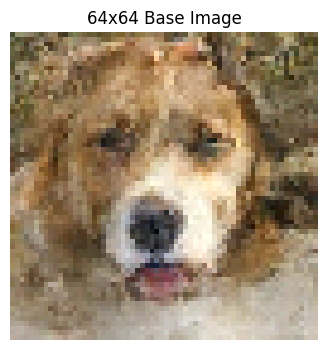


Upsampling to 256x256...


Upsampling: 100%|██████████| 499/499 [01:18<00:00,  6.32it/s]
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0059493184..1.0506061].


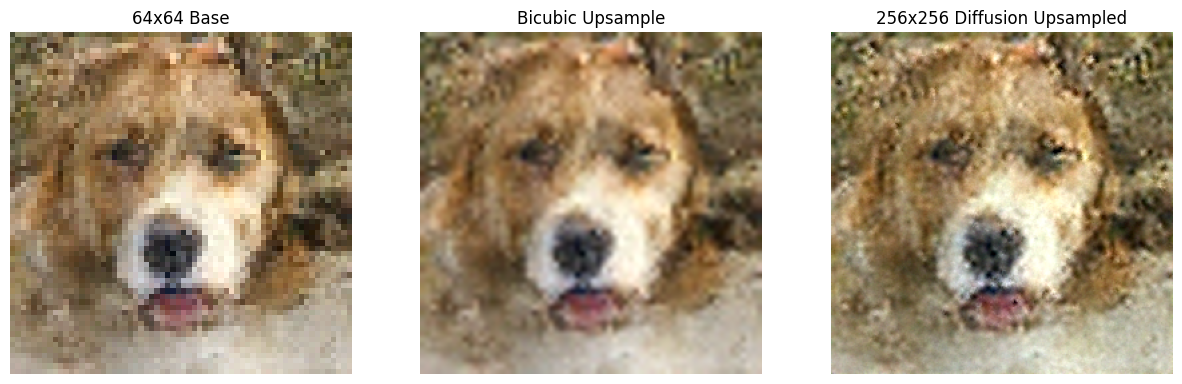

In [82]:
def backward_denoising_upsampler(x_t, pred_noise, t, low_res_conditioning):
    """Denoising step for the upsampler"""
    alpha_t = tf.gather(alpha, t)
    alpha_t_bar = tf.gather(alpha_bar, t)

    eps_coef = (1 - alpha_t) / (1 - alpha_t_bar) ** 0.5  
    mean = 1 / (alpha_t ** 0.5) * (x_t - eps_coef * pred_noise)
    
    var = tf.gather(beta, t)
    z = tf.random.normal(tf.shape(x_t), dtype=tf.float32)

    return mean + (var ** 0.5) * z

def generate_high_res_image():
    """Complete cascading diffusion: 64x64 -> 256x256"""
    
    # STEP 1: Generate 64x64 image using base diffusion model
    print("Generating 64x64 base image...")
    x_64 = tf.random.normal((1, 64, 64, 3), dtype=tf.float32, seed=random.randint(0, 1000))
    
    for i in tqdm(range(0, TIMESTEPS - 1), desc="Base generation"):
        t = tf.expand_dims(tf.constant(TIMESTEPS - i - 1, dtype=tf.int32), 0)
        pred_noise = diffusion_model([x_64, t])
        x_64 = backward_denoising_ddpm(x_64, pred_noise, t)
    
    # Display the 64x64 result
    img_64 = (x_64[0] + 1.0) / 2.0
    img_64 = tf.clip_by_value(img_64, 0.0, 1.0)
    plt.figure(figsize=(4,4))
    plt.imshow(img_64.numpy())
    plt.title("64x64 Base Image")
    plt.axis('off')
    plt.show()
    
    # STEP 2: Upsample to 256x256 using upsampler model
    print("\nUpsampling to 256x256...")
    
    # Bicubic upsample the 64x64 image as conditioning
    low_res_upsampled = tf.image.resize(
        x_64,
        size=[256, 256],
        method='bicubic',
        antialias=True
    )
    
    # Start with pure noise at 256x256
    x_256 = tf.random.normal((1, 256, 256, 3), dtype=tf.float32, seed=random.randint(0, 1000))
    
    # Denoise to get high resolution image
    for i in tqdm(range(0, TIMESTEPS - 1), desc="Upsampling"):
        t = tf.expand_dims(tf.constant(TIMESTEPS - i - 1, dtype=tf.int32), 0)
        t_float = tf.cast(t, dtype=tf.float32)
        t_float = tf.reshape(t_float, (-1, 1))
        
        # Concatenate with bicubic conditioning (same as training)
        model_input = tf.concat([x_256, low_res_upsampled], axis=-1)
        
        # Predict noise
        pred_noise = upscaler_model([model_input, t_float])
        
        # Denoise
        x_256 = backward_denoising_upsampler(x_256, pred_noise, t, low_res_upsampled)
        
        # Optional: visualize progress
        # if i % 100 == 0:
        #     img_progress = (x_256[0] + 1.0) / 2.0
        #     img_progress = tf.clip_by_value(img_progress, 0.0, 1.0)
        #     plt.figure(figsize=(6,6))
        #     plt.imshow(img_progress.numpy())
        #     plt.title(f"Upsampling Step {i}")
        #     plt.axis('off')
        #     plt.show()
    
    # Final result
    img_256 = (x_256[0] + 1.0) / 2.0
    img_256 = tf.clip_by_value(img_256, 0.0, 1.0)
    
    # Display comparison
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img_64.numpy())
    axes[0].set_title("64x64 Base")
    axes[0].axis('off')
    
    axes[1].imshow((low_res_upsampled[0] + 1.0) / 2.0)
    axes[1].set_title("Bicubic Upsample")
    axes[1].axis('off')
    
    axes[2].imshow(img_256.numpy())
    axes[2].set_title("256x256 Diffusion Upsampled")
    axes[2].axis('off')
    plt.show()
    
    return x_256

# Run the complete pipeline
high_res_image = generate_high_res_image()